# environment setup

In [7]:
import pandas as pd

In [1]:
import pickle
import numpy as np


### INCARCAREA DATELOR
class NumpyCompatUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module.startswith("numpy._core"):
            module = module.replace("numpy._core", "numpy.core")
        return super().find_class(module, name)
if np.__version__ >= '2.0.0':
    with open('train_data.pkl', 'rb') as f:
        data = pickle.load(f)
else:
    with open('train_data.pkl', 'rb') as f:
        data = NumpyCompatUnpickler(f).load()

train_image_embeddings = data['train_image_embeddings']
gender_labels = data['gender_labels']
test_image_embeddings = data['test_image_embeddings']

print('-----DATA INFO-----')
print('Shape of train_image_embeddings:', train_image_embeddings.shape)
print('Shape of gender_labels:', gender_labels.shape)
print('Shape of test_image_embeddings:', test_image_embeddings.shape)
print('-----DATA INFO-----')


-----DATA INFO-----
Shape of train_image_embeddings: (15000, 512)
Shape of gender_labels: (15000,)
Shape of test_image_embeddings: (15000, 512)
-----DATA INFO-----


In [13]:
pd.DataFrame(train_image_embeddings).head()

,0,1,2,3,4,5,6,7,8,9,...,502,503,504,505,506,507,508,509,510,511
0,0.076049,-0.088293,0.022239,-0.031006,0.002226,-0.014161,-0.019600,-0.048140,0.038127,-0.040310,...,-0.014730,0.007572,0.019175,-0.002966,0.017067,0.004363,0.042417,0.028308,-0.012883,0.008207
1,-0.013886,-0.026542,0.043444,0.001906,-0.051371,-0.015042,-0.026197,-0.012462,-0.011699,0.014670,...,0.048546,0.020799,0.016957,0.009577,0.045345,-0.023278,-0.022685,0.020598,0.037207,0.019531
2,0.068503,-0.042549,0.043012,-0.003469,-0.019328,-0.005812,-0.003336,-0.043222,0.055114,0.004030,...,-0.028703,-0.037946,0.016874,0.029697,-0.017384,0.089571,0.035184,0.009764,0.005316,0.026929
3,0.005221,-0.070757,0.059485,-0.018228,0.017964,0.035686,0.001186,0.025729,0.021479,0.010088,...,0.005874,0.017254,0.040426,0.076481,-0.025705,0.112636,0.027311,0.000663,0.036855,-0.040074
4,0.041665,-0.061293,0.055807,0.008224,-0.005366,-0.059253,0.032777,-0.019251,0.014213,-0.004150,...,0.010421,0.018058,-0.019113,0.043269,0.034075,0.078906,0.038154,0.041820,-0.012043,0.070275


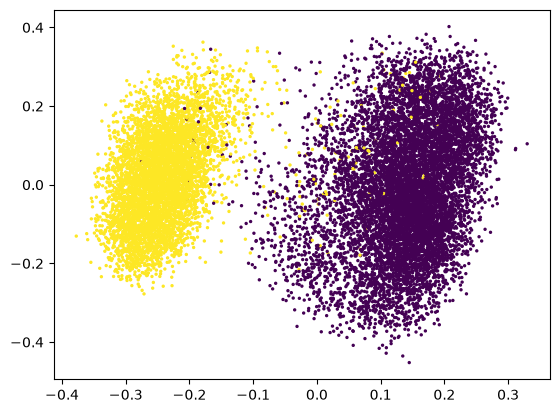

In [16]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

P = PCA(n_components=2).fit_transform(train_image_embeddings)
plt.scatter(P[:, 0], P[:, 1], c=gender_labels, s=2)
plt.show()


In [17]:
print(np.unique(gender_labels, return_counts=True))

(array([0, 1], dtype=int32), array([9466, 5534]))


In [18]:
X = train_image_embeddings
T = test_image_embeddings
y = gender_labels

# axis = 0 inseamna ca facem media pt fiecare din alea 512
mean0 = X[y == 0].mean(axis=0)    
mean1 = X[y == 1].mean(axis=0)     
mid = (mean0 + mean1) / 2

def guess(E):
    # 1 if the embedding is closer to group 1's center, else 0
    d0 = np.linalg.norm(E - mean0, axis=1)
    d1 = np.linalg.norm(E - mean1, axis=1)
    return (d1 < d0).astype(int)

def shift(E, groups):
    out = E.copy()
    for i in range(len(E)):
        if groups[i] == 0:
            out[i] = E[i] - mean0 + mid
        else:
            out[i] = E[i] - mean1 + mid
    return out

print('guess accuracy on train:', (guess(X) == y).mean())

test_groups = guess(T)
debiased_train_image_embeddings = shift(X, y)           
debiased_test_image_embeddings = shift(T, test_groups)   

guess accuracy on train: 0.9906666666666667


In [19]:
# asta e doar verificare

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def gender_check(E, labels):
    acc = cross_val_score(LogisticRegression(max_iter=1000), E, labels, cv=3).mean()
    print('gender predictable with accuracy', round(acc, 3))

gender_check(X, y)                                              # before
gender_check(debiased_train_image_embeddings, y)                # after, train
gender_check(debiased_test_image_embeddings, test_groups)       # after, test (guessed labels)

def kept(E_new, E_old):
    cos = (E_new * E_old).sum(axis=1) / (np.linalg.norm(E_new, axis=1) * np.linalg.norm(E_old, axis=1))
    print('average cosine to original:', round(cos.mean(), 4))

kept(debiased_train_image_embeddings, X)
kept(debiased_test_image_embeddings, T)

gender predictable with accuracy 0.992
gender predictable with accuracy 0.631
gender predictable with accuracy 0.636
average cosine to original: 0.9817
average cosine to original: 0.9817


# submisie

In [20]:
### GENERAREA SUBMISIEI - NU MODIFICATI CODUL DE AICI. MODIFICAREA CODULUI VA REZULTA INTR-O SUBMISIE INVALIDA.
def generate_submission(debiased_train_image_embeddings, debiased_test_image_embeddings, compression=data['compression']):
    train_compression = debiased_train_image_embeddings @ compression.T
    test_compression = debiased_test_image_embeddings @ compression.T
    with open('submission.pkl', 'wb') as f:
        pickle.dump({'train_compression': train_compression, 'test_compression': test_compression}, f)
generate_submission(debiased_train_image_embeddings, debiased_test_image_embeddings)